In [1]:
import phidl
import phidl.geometry as pg
from phidl import quickplot as qp
import numpy as np
import os
from phidl import Device, Path
import phidl.path as pp
from scipy.constants import epsilon_0, mu_0
from scipy.special import ellipk
import phidl.routing as pr

In [2]:
def make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width):
    
    pad = pg.taper(length=pad_size,width1=pad_size,width2=pad_size)
    taper = pg.taper(length=taper_len,width1=pad_size,width2=feedline_width)
    feedline = pg.taper(length=feedline_len,width1=feedline_width,width2=feedline_width)

    feedline_dev = phidl.Device("feedline")
    pad_ref1 = feedline_dev.add_ref(pad)
    taper_ref1 = feedline_dev.add_ref(taper)
    feedline_ref = feedline_dev.add_ref(feedline)
    taper_ref1.connect(1,destination=pad_ref1.ports[2])
    feedline_ref.connect(1,destination=taper_ref1.ports[2])
    taper_ref2 = feedline_dev.add_ref(taper)
    pad_ref2 = feedline_dev.add_ref(pad)
    taper_ref2.connect(2,destination=feedline_ref.ports[2])
    pad_ref2.connect(2,destination=taper_ref2.ports[1])
    feedline_dev.xmax = 0

    return feedline_dev

In [3]:
def make_feedline_contact(
    pad_size = 200,
    taper_len = 100,
    feedline_len = 0,
    feedline_width = 66,
    ground_gap = 2,
):
    """
    TODO: Add ports to couple resonator to!
    """
    feedline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline.x = 0

    pad_size += 100
    feedline_width += 2*ground_gap

    feedline_outline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline_outline.x = 0

    return feedline, feedline_outline

In [4]:
def make_coupling_elbow(
        coupling_length,
        turn_radius = 25,
        space = 100
    ):

    P = Path()
    P.append(pp.straight(coupling_length))
    direction = 1
    P.append(pp.euler(radius=turn_radius, angle=90*direction))
    P.append(pp.straight(space))

    return P

def make_coupling_hammerhead(
        coupling_length,
        coupling_width=5
    ):
    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    return hammerhead

In [5]:
def make_lamda2_res_straight(
    radius=50,
    width=2,
    center_pin_length=3500,
    center_pin_gap = 60,
    coupling_length = 100,
    coupling_width=5,
    hammerhead_gap=2
):

    P = Path()
    P.append(pp.straight(center_pin_length))

    print('total length',P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

total length 350.0


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


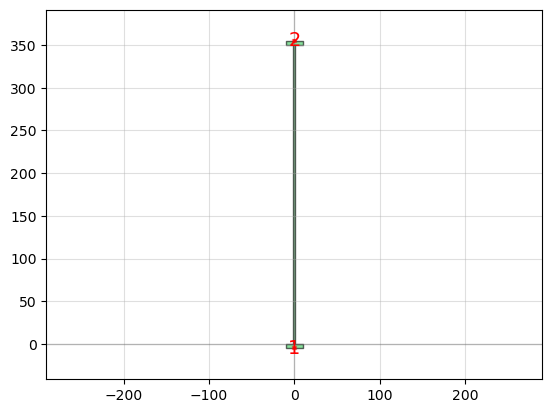

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


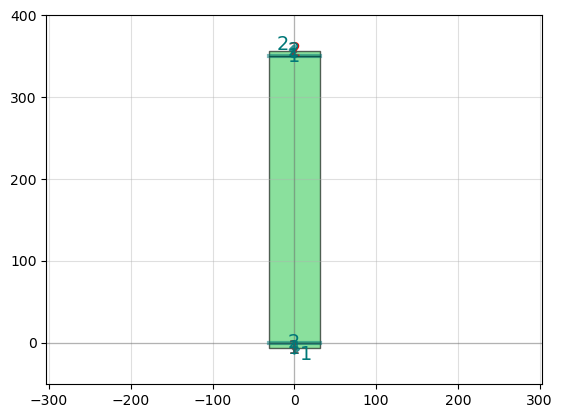

In [6]:
coupled_resonator, coupled_resonator_outline = make_lamda2_res_straight(center_pin_length=350,center_pin_gap=30,coupling_length=20,coupling_width=5)
qp(coupled_resonator)
qp(coupled_resonator_outline)

In [7]:
def calculate_segment_length(
    L_len=400,
    radius=200
):
    P = Path()
    direction = -1
    P.append(pp.straight(2*radius))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180*direction))
    P.append(pp.straight(L_len))
    direction *= -1
    P.append(pp.arc(radius=radius, angle=-90*direction))
    return P.length()

In [8]:
#TODO: Define a sub!

In [9]:
def make_lamda2_res_meander(
    L_len=300,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
    coupling_length = 20,
    coupling_width=5,
    space=100,
    hammerhead_gap=2
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [10]:
def smooth_device(r,smoothing_radius=2):
    r_round = phidl.Device("round_r")
    for port in r.ports.values():
        r_round.add_port(port)
    dev = pg.union(r, precision=1e-6, layer=0)   # instead of boolean with B=None
    dev.flatten()
    for ps in dev.polygons:
        ps.fillet(radius=smoothing_radius)
        for pts in ps.polygons:          # a PolygonSet can hold several polygons
            r_round.add_polygon(pts, layer=0)
    return r_round

### Define resonators!

In [25]:
center_pin_length=3000
center_pin_gap=60
width=2
hammerhead_gap=2
L_len=250
radius=100

readout_res, readout_res_outline = make_lamda2_res_meander(
    center_pin_length=center_pin_length,
    center_pin_gap=center_pin_gap,
    width=width,
    hammerhead_gap=hammerhead_gap,
    L_len=L_len,
    radius=radius)

# readout_res, readout_res_outline = make_lamda2_res_straight(
#     center_pin_length=3000,
#     center_pin_gap=60,
#     width=2,
#     coupling_length=20,
#     coupling_width=5
#     )

driven_res, driven_res_outline = make_lamda2_res_straight(
    center_pin_length=500,
    center_pin_gap=60,
    coupling_length=20,
    coupling_width=5
    )

pad_size = 250
taper_len = 100
feedline_len = 6000
feedline_width = 66
ground_gap = 2

feedline, feedline_outline = make_feedline_contact(    
    pad_size = pad_size,
    taper_len = taper_len,
    feedline_len = feedline_len,
    feedline_width = feedline_width,
    ground_gap = ground_gap
    )

feedline.add_port(1,midpoint=(0,feedline_width/2),orientation=90)
groundplane = pg.rectangle(size=(10000,10000))

3000.0
total length 500.00000000000006


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


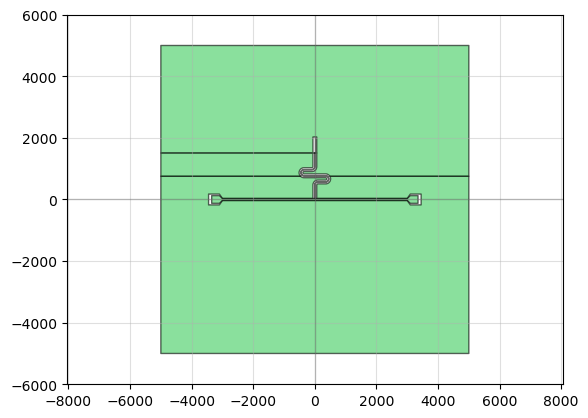

'coupled_res.gds'

In [26]:
RESONATOR_GAP = 10
smooth = False

chip_layout = phidl.Device('chip_layout')
groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

if smooth:
    feedline = smooth_device(feedline)
    readout_res = smooth_device(readout_res)
    driven_res = smooth_device(driven_res)

feedline_outline = smooth_device(feedline_outline)
readout_res_outline = smooth_device(readout_res_outline)
driven_res_outline = smooth_device(driven_res_outline)

# Subtract the ground plane gaps.
feedline_ref = chip_layout.add_ref(feedline)
feedline_outline_ref = chip_layout.add_ref(feedline_outline)

readout_res_outline_ref = chip_layout.add_ref(readout_res_outline)
readout_res_ref = chip_layout.add_ref(readout_res)

readout_res_outline_ref.x = feedline.ports[1].midpoint[0]
readout_res_outline_ref.ymin = feedline.ports[1].midpoint[1] 
readout_res_ref.x = feedline.ports[1].midpoint[0]
readout_res_ref.ymin = feedline.ports[1].midpoint[1] + hammerhead_gap

driven_res_ref = chip_layout.add_ref(driven_res)
driven_res_outline_ref = chip_layout.add_ref(driven_res_outline)

driven_res_outline_ref.x = readout_res_outline_ref.ports[2].midpoint[0]
driven_res_outline_ref.ymin = readout_res_outline_ref.ports[2].midpoint[1] + RESONATOR_GAP
driven_res_ref.x = readout_res_outline_ref.ports[2].midpoint[0] 
driven_res_ref.ymin = readout_res_outline_ref.ports[2].midpoint[1] + hammerhead_gap + RESONATOR_GAP

chip_layout = pg.boolean(chip_layout,feedline_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,driven_res_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,readout_res_outline_ref,operation='A-B')

chip_layout = pg.boolean(chip_layout,readout_res_ref,operation='A+B')
chip_layout = pg.boolean(chip_layout,feedline_ref,operation='A+B')
chip_layout = pg.boolean(chip_layout,driven_res_ref,operation='A+B')

qp(chip_layout)
chip_layout.write_gds('coupled_res.gds')

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


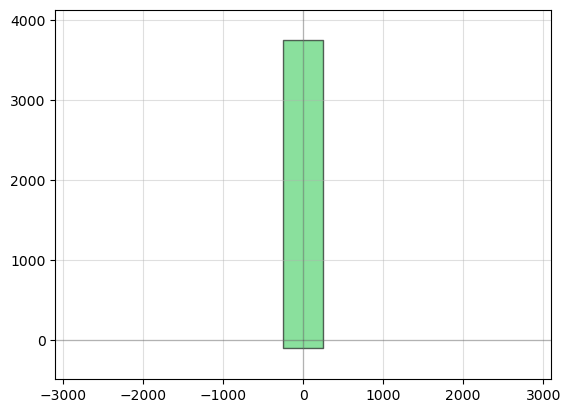

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


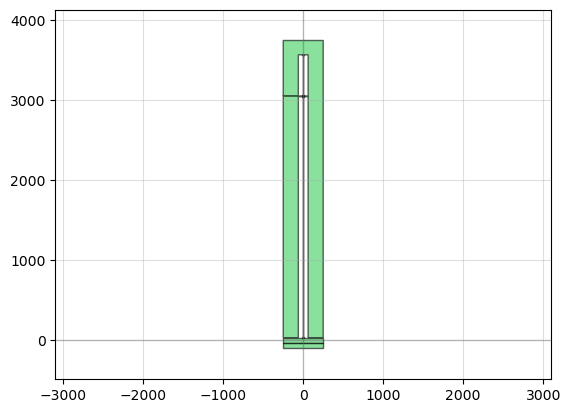

'avoided_crossing.gds'

In [24]:
bbox = [
    [-250,-100],  # xmin - pad, ymin - pad
    [250, 3750]   # xmax + pad, ymax + pad
]
bbox = pg.bbox(bbox)
qp(bbox)

cutout = pg.boolean(bbox,chip_layout,operation='and')
qp(cutout)

cutout.write_gds('avoided_crossing.gds')